In [1]:
!jupyter nbconvert --to script ror_prob_test.ipynb

%load_ext autoreload
%autoreload 2

from compute_ror_prob import compute_ror_with_gbm
from functions import calculate_l_v
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t
from sklearn.preprocessing import PolynomialFeatures
from functools import partial
import warnings
from scipy.optimize import minimize


warnings.filterwarnings(
    "ignore",
    category=pd.errors.PerformanceWarning
)

[NbConvertApp] Converting notebook ror_prob_test.ipynb to script
[NbConvertApp] Writing 13261 bytes to ror_prob_test.py


In [2]:
def load_cleaned_btc_data():
    btc_df = pd.read_csv("data/coinbaseUSD_1-min_data.csv")

    # Filter data from 01-01-2017 to latest data and drop NaNs
    btc_df['Date'] = pd.to_datetime(btc_df['Date'], utc=True)
    btc_df = btc_df.set_index("Date").sort_index()
    start_date = pd.to_datetime("2017-01-01", utc=True)
    btc_df = btc_df[btc_df.index >= start_date]
    btc_df = btc_df.dropna()

    btc_df['Price'] = (btc_df['High'] + btc_df['Low']) / 2.0
    return btc_df

btc_df = load_cleaned_btc_data()

In [3]:
def define_training_constants():
    # Constants for time ranges, percentage price changes, and risk of ruin bin edges
    # deltas = [10, 30, 60, 120, 300] # in minutes
    # ps = [-0.005, -0.01, -0.02, -0.05] # percentage changes (-0.05, -0.1 seem rly rly small)
    deltas = [5, 25, 50, 100, 120] # in minutes
    ps = [-0.005, -0.01, -0.015, -0.02, -0.025] # percentage changes (-0.05, -0.1 seem rly rly small)
    ror_bin_edges = [0.0, 0.005, 0.01, 0.02, 0.03, 0.04, 0.05] + list(np.arange(0.1, 1.01, 0.05))  # probability of ror
    return deltas, ps, ror_bin_edges

deltas, ps, ror_bin_edges = define_training_constants()

In [4]:
calculate_l_v(np.array([[1 for _ in range(2)] for _ in range(6)]), 2, 1, 2)

(7, 7.025069444444444)

In [21]:
def determine_gbm_params(btc_df, deltas, c_l_v=None):
    # Calculate rolling mean and std (GBM)
    btc_df['log_returns'] = np.log(btc_df['Price'] / btc_df['Price'].shift(1))
    # new_cols = {}
    for d in deltas:
        for p in ps:
            # l_eq takes in d, p and outputs rolling window length, v_eq takes in and outputs df
            if c_l_v is not None:
                l, v = c_l_v(d, p)
            else:
                l = d
                v = 1

            rolling_mean = btc_df['log_returns'].rolling(f"{l}min").mean()
            rolling_std = btc_df['log_returns'].rolling(f"{l}min").std()
            btc_df[f"mu_{d}min,{p}price"] = rolling_mean + 0.5 * rolling_std ** 2
            btc_df[f"sigma_{d}min,{p}price"]  = rolling_std
            btc_df[f"kurt_{d}min,{p}price"] = v
    
    btc_df = btc_df.dropna()
    return btc_df

W_star = np.array([[10.009467473030782, 7.646548230654321], [3.65189065265735, 2.1831277568386116], [3.627243428142196, 4.509796213416398], [8.657113676623583, 5.258895555125257], [5.628179859928944, 2.2082482152286698], [10.05912389002543, 2.167535522464349], [4.974406215942629, 9.354025705380616], [9.619450202699198, 6.454095199805068], [5.865453905684857, 1.5705783589879885], [8.839070543899561, 7.289496804763678]])
btc_df = determine_gbm_params(btc_df, deltas, partial(calculate_l_v, W_star, 3))

In [22]:
def compute_and_bucket_ror_probs(btc_df, deltas, ps, ror_bin_edges, sampling_prop=1):
    # Determine true delta indices
    td_deltas = np.array([np.timedelta64(int(d), 'm') for d in deltas])
    timestamps_broadcasted = np.broadcast_to(btc_df.index.values, (len(deltas), len(btc_df)))
    deltas_broadcasted = td_deltas[:, np.newaxis]
    target_final_times = timestamps_broadcasted + deltas_broadcasted
    flat_search = np.searchsorted(btc_df.index.values, target_final_times.ravel(), side='left')
    all_target_idx = flat_search.reshape((len(deltas), len(btc_df)))
    all_target_idx = np.minimum(all_target_idx, len(btc_df) - 1)

    # Compute true deltas and true price changes
    true_final_times = btc_df.index.values.astype('int64')[all_target_idx]
    true_deltas = (true_final_times - btc_df.index.values.astype('int64')[np.newaxis, :]) / (1e9 * 60.0)
    true_price_changes = (btc_df['Price'].values[all_target_idx] - btc_df['Price'].values[np.newaxis, :]) / btc_df['Price'].values[np.newaxis, :]

    empirical_data_buckets = np.zeros((len(deltas), len(ps), len(ror_bin_edges) - 1, 2), dtype=np.int64)

    batch_indices = np.random.choice(len(btc_df), size=int(sampling_prop * len(btc_df)), replace=False)
    batch_mask = np.zeros(len(btc_df), dtype=bool)
    batch_mask[batch_indices] = True

    for d in range(len(deltas)):
        delta = true_deltas[d, :][batch_mask].ravel()
        true_price_change = true_price_changes[d, :][batch_mask].ravel()
        p_0 = btc_df['Price'].to_numpy()[batch_mask].ravel()

        for p in range(len(ps)):
            mu = btc_df[f"mu_{deltas[d]}min,{ps[p]}price"].to_numpy()[batch_mask].ravel()
            sigma = btc_df[f"sigma_{deltas[d]}min,{ps[p]}price"].to_numpy()[batch_mask].ravel()
            nu_arr = btc_df[f"kurt_{deltas[d]}min,{ps[p]}price"].to_numpy()[batch_mask].ravel()
            
            ror_arr = compute_ror_with_gbm(p_f = (1 + ps[p]) * p_0, delta = delta, mu = mu, sigma = sigma, p_0 = p_0, nu_arr= nu_arr, testing=True)

            valid_mask = ~np.isnan(ror_arr)
            valid_ror = ror_arr[valid_mask]
            valid_true_price_change = true_price_change[valid_mask]

            bin_idx_arr = np.digitize(valid_ror, ror_bin_edges) - 1
            success_mask = (valid_true_price_change < ps[p])
            total_counts = np.bincount(bin_idx_arr, minlength=len(ror_bin_edges) - 1)
            success_counts = np.bincount(bin_idx_arr, weights=success_mask.astype(int), minlength=len(ror_bin_edges) - 1)

            empirical_data_buckets[d, p, :, 0] = success_counts
            empirical_data_buckets[d, p, :, 1] = total_counts

        # print(f"Completed delta {d+1}/{len(deltas)}")
    
    return empirical_data_buckets

empirical_data_buckets = compute_and_bucket_ror_probs(btc_df, deltas, ps, ror_bin_edges, sampling_prop=1)

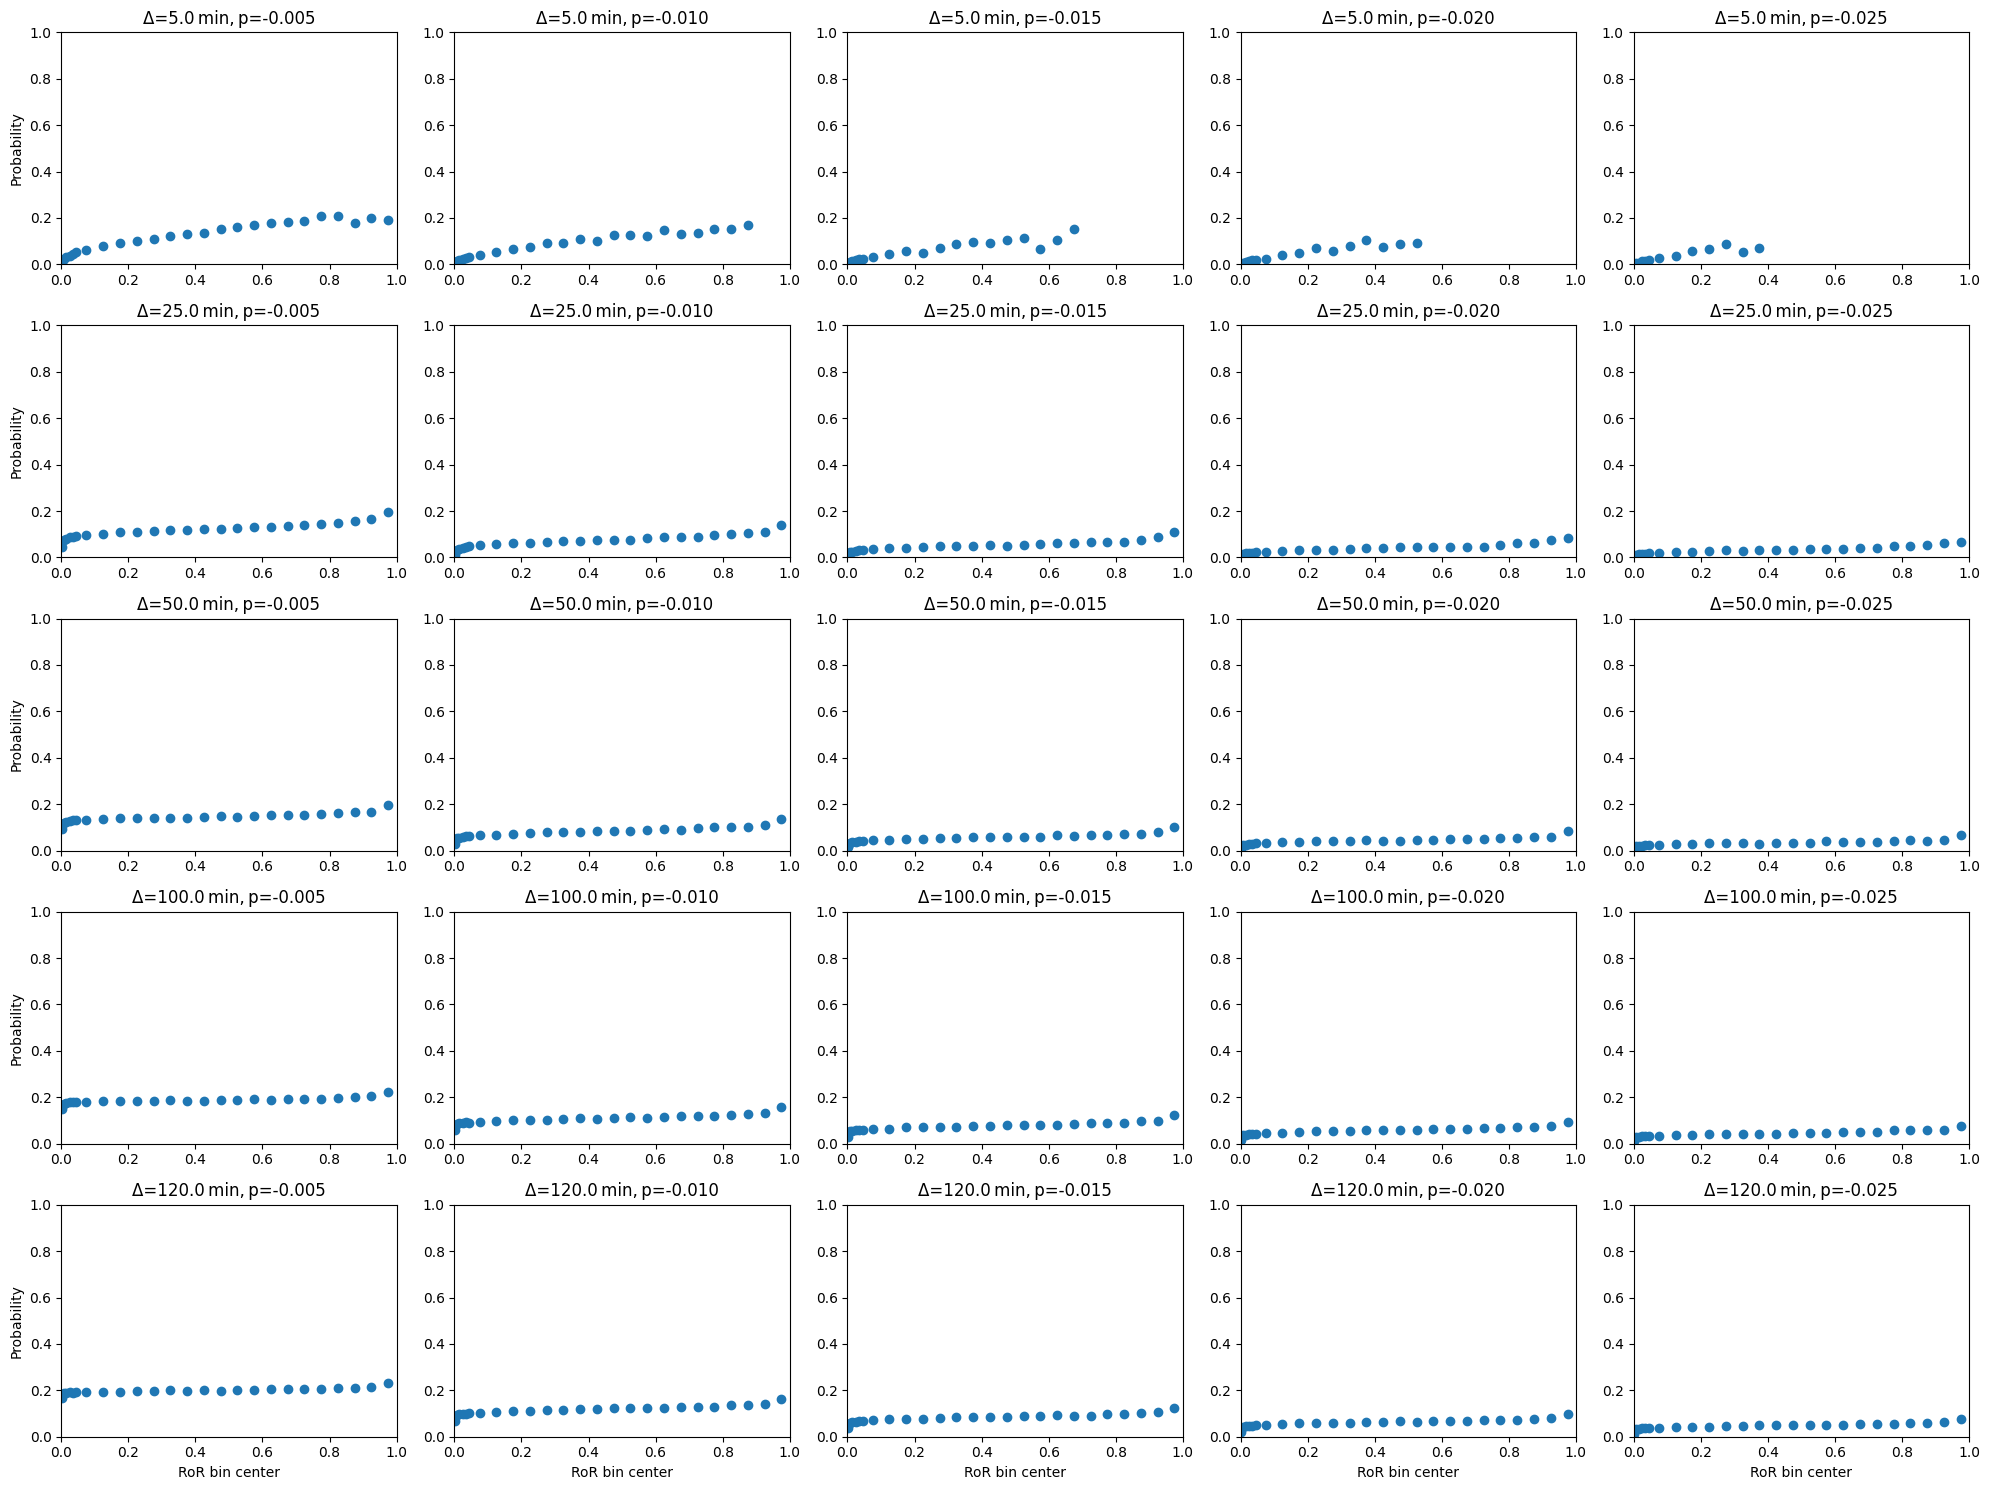

In [23]:
# Determine dimensions
n_deltas, n_ps, n_bins, _ = empirical_data_buckets.shape

ror_bin_edges = np.asarray(ror_bin_edges, dtype=float)
deltas = np.asarray(deltas, dtype=float)
ps = np.asarray(ps, dtype=float)    

# Compute bin centers from edges
bin_centers = (ror_bin_edges[:-1] + ror_bin_edges[1:]) / 2.0  # shape (n_bins,)

# Create a grid of subplots: rows = n_deltas, columns = n_ps
fig, axes = plt.subplots(
    n_deltas,
    n_ps,
    figsize=(4 * n_ps, 3 * n_deltas),
    squeeze=False  # always returns 2D axes array
)

# Loop over each subplot position
for i in range(n_deltas):
    for j in range(n_ps):
        ax = axes[i, j]

        # Extract counts for this (delta, p)
        success_counts = empirical_data_buckets[i, j, :, 0]  # shape (n_bins,)
        total_counts   = empirical_data_buckets[i, j, :, 1]  # shape (n_bins,)

        # Compute probability; need at least 30 samples per bin to compute probability
        with np.errstate(divide='ignore', invalid='ignore'):
            prob = np.where(total_counts > 200, success_counts / total_counts, np.nan)
            # prob = np.divide(success_counts, total_counts)

        # Plot probability vs. bin center
        ax.scatter(bin_centers, prob, marker='o')
        ax.set_title(f"Δ={deltas[i]} min, p={ps[j]:.3f}")
        ax.set_xlim(0, 1)

        # Label axes on outermost plots only
        if i == n_deltas - 1:
            ax.set_xlabel("RoR bin center")
        if j == 0:
            ax.set_ylabel("Probability")

        # Set consistent y‐limits [0,1]
        ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [8]:
rows = [['Delta', 'Price Change'] + ror_bin_edges]
for d_idx in range(len(deltas)):
    for p_idx in range(len(ps)):
        rows.append([deltas[d_idx], ps[p_idx]] + empirical_data_buckets[d_idx, p_idx, :, 0].tolist())
        rows.append(['', ''] + empirical_data_buckets[d_idx, p_idx, :, 1].tolist())

df = pd.DataFrame(rows)
df.to_csv("results/compute_ror_with_gbm.csv", index=False)
print(df.head())

UFuncTypeError: ufunc 'add' did not contain a loop with signature matching types (dtype('<U12'), dtype('float64')) -> None

In [25]:
def calculate_error(btc_df, deltas, ps, ror_bin_edges, c_l_v, test_probs, sampling_prop=1):
    btc_df = determine_gbm_params(btc_df, deltas, c_l_v)
    empirical_data_buckets = compute_and_bucket_ror_probs(btc_df, deltas, ps, ror_bin_edges, sampling_prop)

    success_counts = empirical_data_buckets[:, :, :, 0]
    total_counts = empirical_data_buckets[:, :, :, 1]
    with np.errstate(divide='ignore', invalid='ignore'):
        empirical_probs = np.where(total_counts > 200, success_counts / total_counts, np.nan)
        # empirical_probs = np.divide(success_counts, total_counts)
    empirical_probs[total_counts == 0] = np.nan
    mse = np.nanmean(abs(empirical_probs - test_probs) ** 4)
    return mse

In [26]:
## Train for l and w
test_probs = np.array([[[(ror_bin_edges[i] + ror_bin_edges[i + 1]) / 2.0 for i in range(len(ror_bin_edges) - 1)] for _ in range(len(ps))] for _ in range(len(deltas))])

btc_df = load_cleaned_btc_data()
deltas, ps, ror_bin_edges = define_training_constants()

In [ ]:
h = 1e-5
deg = 1
W_t = np.zeros(((deg + 2) * (deg + 1) // 2, 2), float)
W_prev = None
# W_t = np.array([[10.009467473030782, 7.646548230654321], [3.65189065265735, 2.1831277568386116], [3.627243428142196, 4.509796213416398], [8.657113676623583, 5.258895555125257], [5.628179859928944, 2.2082482152286698], [10.05912389002543, 2.167535522464349], [4.974406215942629, 9.354025705380616], [9.619450202699198, 6.454095199805068], [5.865453905684857, 1.5705783589879885], [8.839070543899561, 7.289496804763678]])
W_t = np.array([[10.338096075263444, 10.042785946625758], [6.589816035454418, 1.5059349557070776], [5.247507611081495, 6.27787181763012]])
curr_mse = float('inf')
iter = 0

# Alpha
a = 0.1
A = 100.0
a_exp = 0.50
def alpha(k):
    return a

def h_func(k):
    return h

# Adam parameters
m = np.zeros_like(W_t)
v = np.zeros_like(W_t)
beta1, beta2 = 0.9, 0.999
eps = 1e-8
mse = [float('inf')]
step_sizes = []

# Sample multiple initialization W_1 to find min starting point
for i in range(5):
    print(f"Testing W_1 iter: {i}")
    W_0 = np.random.rand((deg + 2) * (deg + 1) // 2, 2) * 10
    mse_0 = calculate_error(btc_df, deltas, ps, ror_bin_edges, partial(calculate_l_v, W_0, deg), test_probs)
    print(f"W_0: {W_0}, MSE: {mse_0}")
    if mse_0 < mse[0]:
        mse[0] = mse_0
        W_t = W_0

while True:
    iter += 1
    print(f"Iteration {iter}")
    print(f"W_{iter}: {W_t.tolist()}")

    # Estimate gradient with Simultaneous Perturbation Stochastic Approximation (SPSA)
    print(f"Estimating gradient")
    grad_estimates = []
    for i in range(5):
        perturbation = np.round(np.random.rand((deg + 2) * (deg + 1) // 2, 2)) * 2 - 1
        mse_pos = calculate_error(btc_df, deltas, ps, ror_bin_edges, partial(calculate_l_v, W_t + h_func(iter) * perturbation, deg), test_probs, sampling_prop=0.2)
        mse_neg = calculate_error(btc_df, deltas, ps, ror_bin_edges, partial(calculate_l_v, W_t - h_func(iter) * perturbation, deg), test_probs, sampling_prop=0.2)
        grad_estimates.append((mse_pos - mse_neg) / ((2 * h_func(iter)) * perturbation))

    grad_t = np.array(grad_estimates).mean(axis=0)

    # update biased first & second moment estimates
    m = beta1 * m + (1 - beta1) * grad_t
    v = beta2 * v + (1 - beta2) * (grad_t ** 2)

    # bias correction
    m_hat = m / (1 - beta1 ** iter)
    v_hat = v / (1 - beta2 ** iter)

    W_prev = W_t
    # step = alpha(iter) * m_hat/(np.sqrt(v_hat) + eps)
    step = alpha(iter) * grad_t
    W_t -= step
    # W_t = np.clip(W_t, 1e-6, None)
    curr_mse = calculate_error(btc_df, deltas, ps, ror_bin_edges, partial(calculate_l_v, W_t, deg), test_probs)
    mse.append(curr_mse)

    # if curr_mse > mse[-2]:
    #     W_t = W_prev
    #     step /= 2
    #     W_t -= step
    #     W_t = np.clip(W_t, 1e-6, None)
    #     curr_mse = calculate_error(btc_df, deltas, ps, ror_bin_edges, partial(calculate_l_v, W_t, deg), test_probs)
    #     if curr_mse > mse[-2]:
    #         print("Converged")
    #         break
    #     mse[-1] = curr_mse
    
    print(f"alpha- {alpha(iter)}")
    print(f"Current MSE: {curr_mse}")
    print(f"Gradient: {grad_t}")
    print(f"MSE: {mse}")
    step_sizes.append(np.linalg.norm(step))
    print(f"‖step‖ = {step_sizes[-1]:.3e}")


Testing W_1 iter: 0


C:\Users\eshan\AppData\Local\Temp\ipykernel_3556\2063072922.py:11: RuntimeWarning: Mean of empty slice
  mse = np.nanmean(abs(empirical_probs - test_probs) ** 4)


W_0: [[1.07666928 6.38236449]
 [3.58099892 4.35941198]
 [2.94695935 2.63189378]], MSE: nan
Testing W_1 iter: 1
W_0: [[1.73283554 7.42982944]
 [6.30054239 0.22972444]
 [3.69745556 4.06147667]], MSE: 0.11137524963005595
Testing W_1 iter: 2


C:\Users\eshan\AppData\Local\Temp\ipykernel_3556\2063072922.py:11: RuntimeWarning: Mean of empty slice
  mse = np.nanmean(abs(empirical_probs - test_probs) ** 4)


W_0: [[1.62488797 5.2514518 ]
 [6.52036788 5.06582741]
 [4.70251308 6.0663973 ]], MSE: nan
Testing W_1 iter: 3
W_0: [[8.9831879  7.31714841]
 [5.74213066 4.59935636]
 [6.05682718 8.31486001]], MSE: 0.0893143378269133
Testing W_1 iter: 4
W_0: [[2.2045019  1.5261763 ]
 [1.65805876 3.84985749]
 [0.14307761 8.0666838 ]], MSE: 0.11407316760951153
Iteration 1
W_1: [[8.983187904281284, 7.317148412448217], [5.7421306628577, 4.5993563555218], [6.056827181164951, 8.314860010368712]]
Estimating gradient
Hyperparamters: alpha- 0.1, m_hat- [[-3.14096316  2.74972824]
 [-2.15795308 17.9191637 ]
 [ 3.14096316 -9.02982461]], v_hat- [[  9.86564958   7.56100538]
 [  4.65676148 321.09642758]
 [  9.86564958  81.5377325 ]]
Current MSE: 0.08889126823355638
Gradient: [[-3.14096316  2.74972824]
 [-2.15795308 17.9191637 ]
 [ 3.14096316 -9.02982461]]
MSE: [0.0893143378269133, 0.08889126823355638]
‖step‖ = 2.085e+00
Iteration 2
W_2: [[9.297284220373742, 7.042175588781945], [5.957925970579608, 2.8074399858878465],